In [1]:
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx

from eigenpairflow import eigenpairtrack
from eigenpairflow.graph import create_n_partite_graph
from eigenpairflow.magnitude import (
    calculate_magnitudes,
    calculate_pseudo_magnitudes,
    get_zero_indices,
    plot_magnitudes,
)
from eigenpairflow.visualization import (
    plot_tracking_results,
    plot_eigenvectors_rotation
)

In [2]:
partition = [3, 2, 2, 4]
edge_lengths_dict = {(0, 1): 2.0, (1, 2): 1.0, (2, 3): 3.0}
G = create_n_partite_graph(partition, edge_lengths_dict)

# Calculate the graph distance matrix using networkx
D_graph = nx.floyd_warshall_numpy(G)

G, D_graph

(<networkx.classes.graph.Graph at 0x11afb80e0>,
 array([[0.        , 1.        , 1.        , 0.5       , 0.5       ,
         1.5       , 1.5       , 1.83333333, 1.83333333, 1.83333333,
         1.83333333],
        [1.        , 0.        , 1.        , 0.5       , 0.5       ,
         1.5       , 1.5       , 1.83333333, 1.83333333, 1.83333333,
         1.83333333],
        [1.        , 1.        , 0.        , 0.5       , 0.5       ,
         1.5       , 1.5       , 1.83333333, 1.83333333, 1.83333333,
         1.83333333],
        [0.5       , 0.5       , 0.5       , 0.        , 1.        ,
         1.        , 1.        , 1.33333333, 1.33333333, 1.33333333,
         1.33333333],
        [0.5       , 0.5       , 0.5       , 1.        , 0.        ,
         1.        , 1.        , 1.33333333, 1.33333333, 1.33333333,
         1.33333333],
        [1.5       , 1.5       , 1.5       , 1.        , 1.        ,
         0.        , 0.66666667, 0.33333333, 0.33333333, 0.33333333,
         0.333

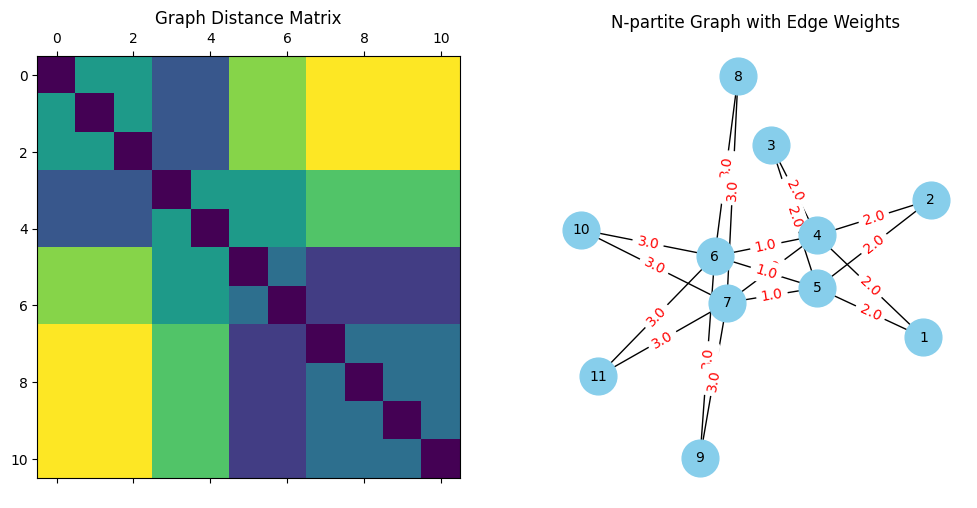

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Left subplot: Heatmap of the distance matrix
im = ax[0].matshow(D_graph, cmap='viridis')
ax[0].set_title("Graph Distance Matrix")

# Right subplot: NetworkX graph plot with edge weights
pos = nx.fruchterman_reingold_layout(G, weight='weight', k=0.5/np.sqrt(G.order()))
nx.draw(G, pos, ax=ax[1], with_labels=True, node_color='skyblue', node_size=700, edge_color='k', linewidths=1, font_size=10)
ax[1].set_title("N-partite Graph with Edge Weights")

# Create edge labels dictionary from graph edges and their weights
graph_edge_labels = {(u, v): d['length'] for u, v, d in G.edges(data=True)}
nx.draw_networkx_edge_labels(G, pos, edge_labels=graph_edge_labels, ax=ax[1], font_color='red')

plt.show()

Indices of zero eigenvalues: [0, 1]


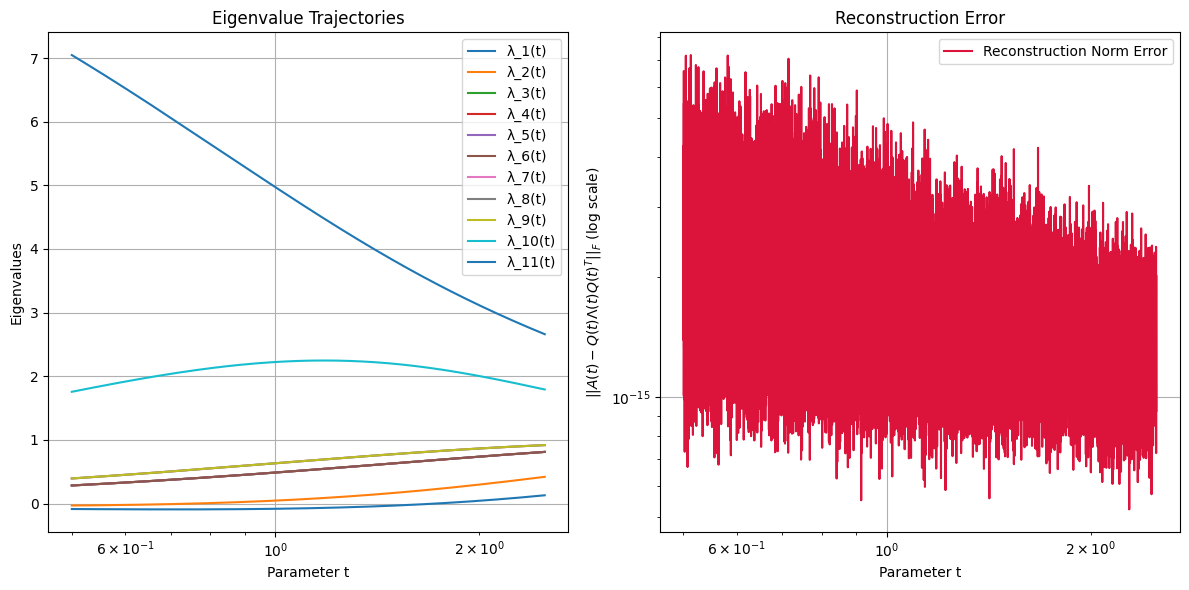

<Figure size 640x480 with 0 Axes>

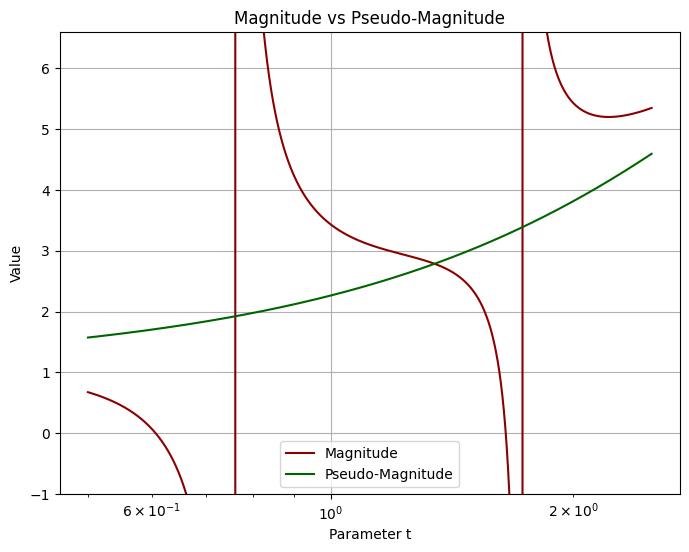

<Figure size 640x480 with 0 Axes>

In [4]:
# Define matrix functions based on the graph distance matrix
def A_func_graph(t):
    return np.exp(-t * D_graph)

def dA_func_graph(t):
    return -D_graph * np.exp(-t * D_graph)

# --- 2. Run the Eigenpair Tracking ---
t_start, t_end = 2.5, 5.0e-1
t_eval = np.geomspace(t_start, t_end, 30000)
result = eigenpairtrack(
    A_func_graph, dA_func_graph, (t_start, t_end), t_eval,
    solver_method='DOP853',
    correction_method='ogita_aishima'
)

zero_indices_graph = get_zero_indices(result.Lambdas)
print(f"Indices of zero eigenvalues: {zero_indices_graph}")

mag = calculate_magnitudes(result.Qs, result.Lambdas, D_graph)
pmag = calculate_pseudo_magnitudes(result.Qs, result.Lambdas, D_graph, zero_indices_graph)

# Plot tracking results (eigenvalues)
plot_tracking_results(result)
plt.suptitle("Eigenvalue Tracking Results (Graph Matrix)")
plt.show()

# Plot calculated magnitudes
plot_magnitudes(result.t_eval, mag, pmag)
plt.suptitle("Calculated Magnitudes (Graph Matrix)")
plt.show()

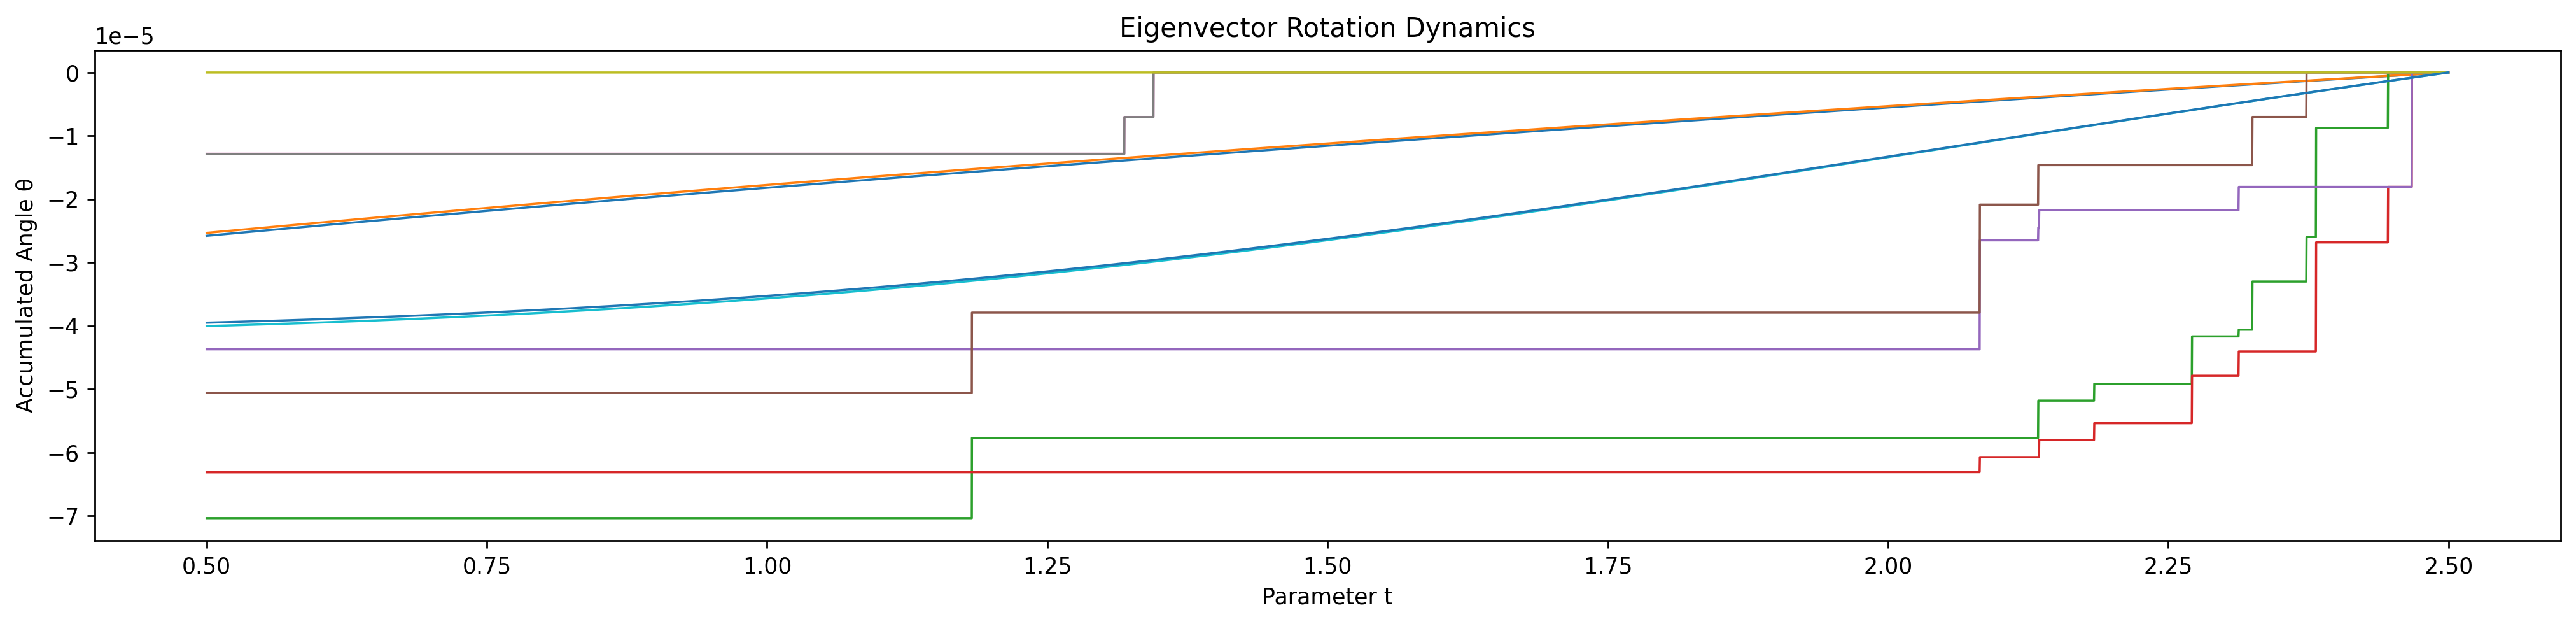

In [5]:
def plot_eigenvectors_rotation(
    result, ax=None
):
    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(8, 6))
        show_plot = True
    else:
        show_plot = False

    if result.Qs is not None and result.t_eval is not None:
        t = result.t_eval
        t_index = np.arange(len(t) - 1)
        # [t_index, row_index, column_index]
        eigenvecs = np.array(result.Qs)
        cosines = np.sum(eigenvecs[t_index + 1] * eigenvecs[t_index], axis=1)
        cosines = np.where(cosines >= 1.0, 1.0, cosines)
        cosines = np.where(cosines <= -1.0, -1.0, cosines)
        thetas = np.arccos(cosines)
        dt = (t[t_index + 1] - t[t_index])[:, None]
        ax.plot(t[1:], np.add.accumulate(thetas * dt), lw=1, label=np.arange(thetas.shape[1]))
        ax.set_title("Eigenvector Rotation Dynamics")
        ax.set_xlabel("Parameter t")
        ax.set_ylabel("Accumulated Angle θ")

    if show_plot:
        plt.show()

    return ax

ax = plt.subplots(1, 1, figsize=(20, 4), dpi=250)[1]
plot_eigenvectors_rotation(result, ax=ax);

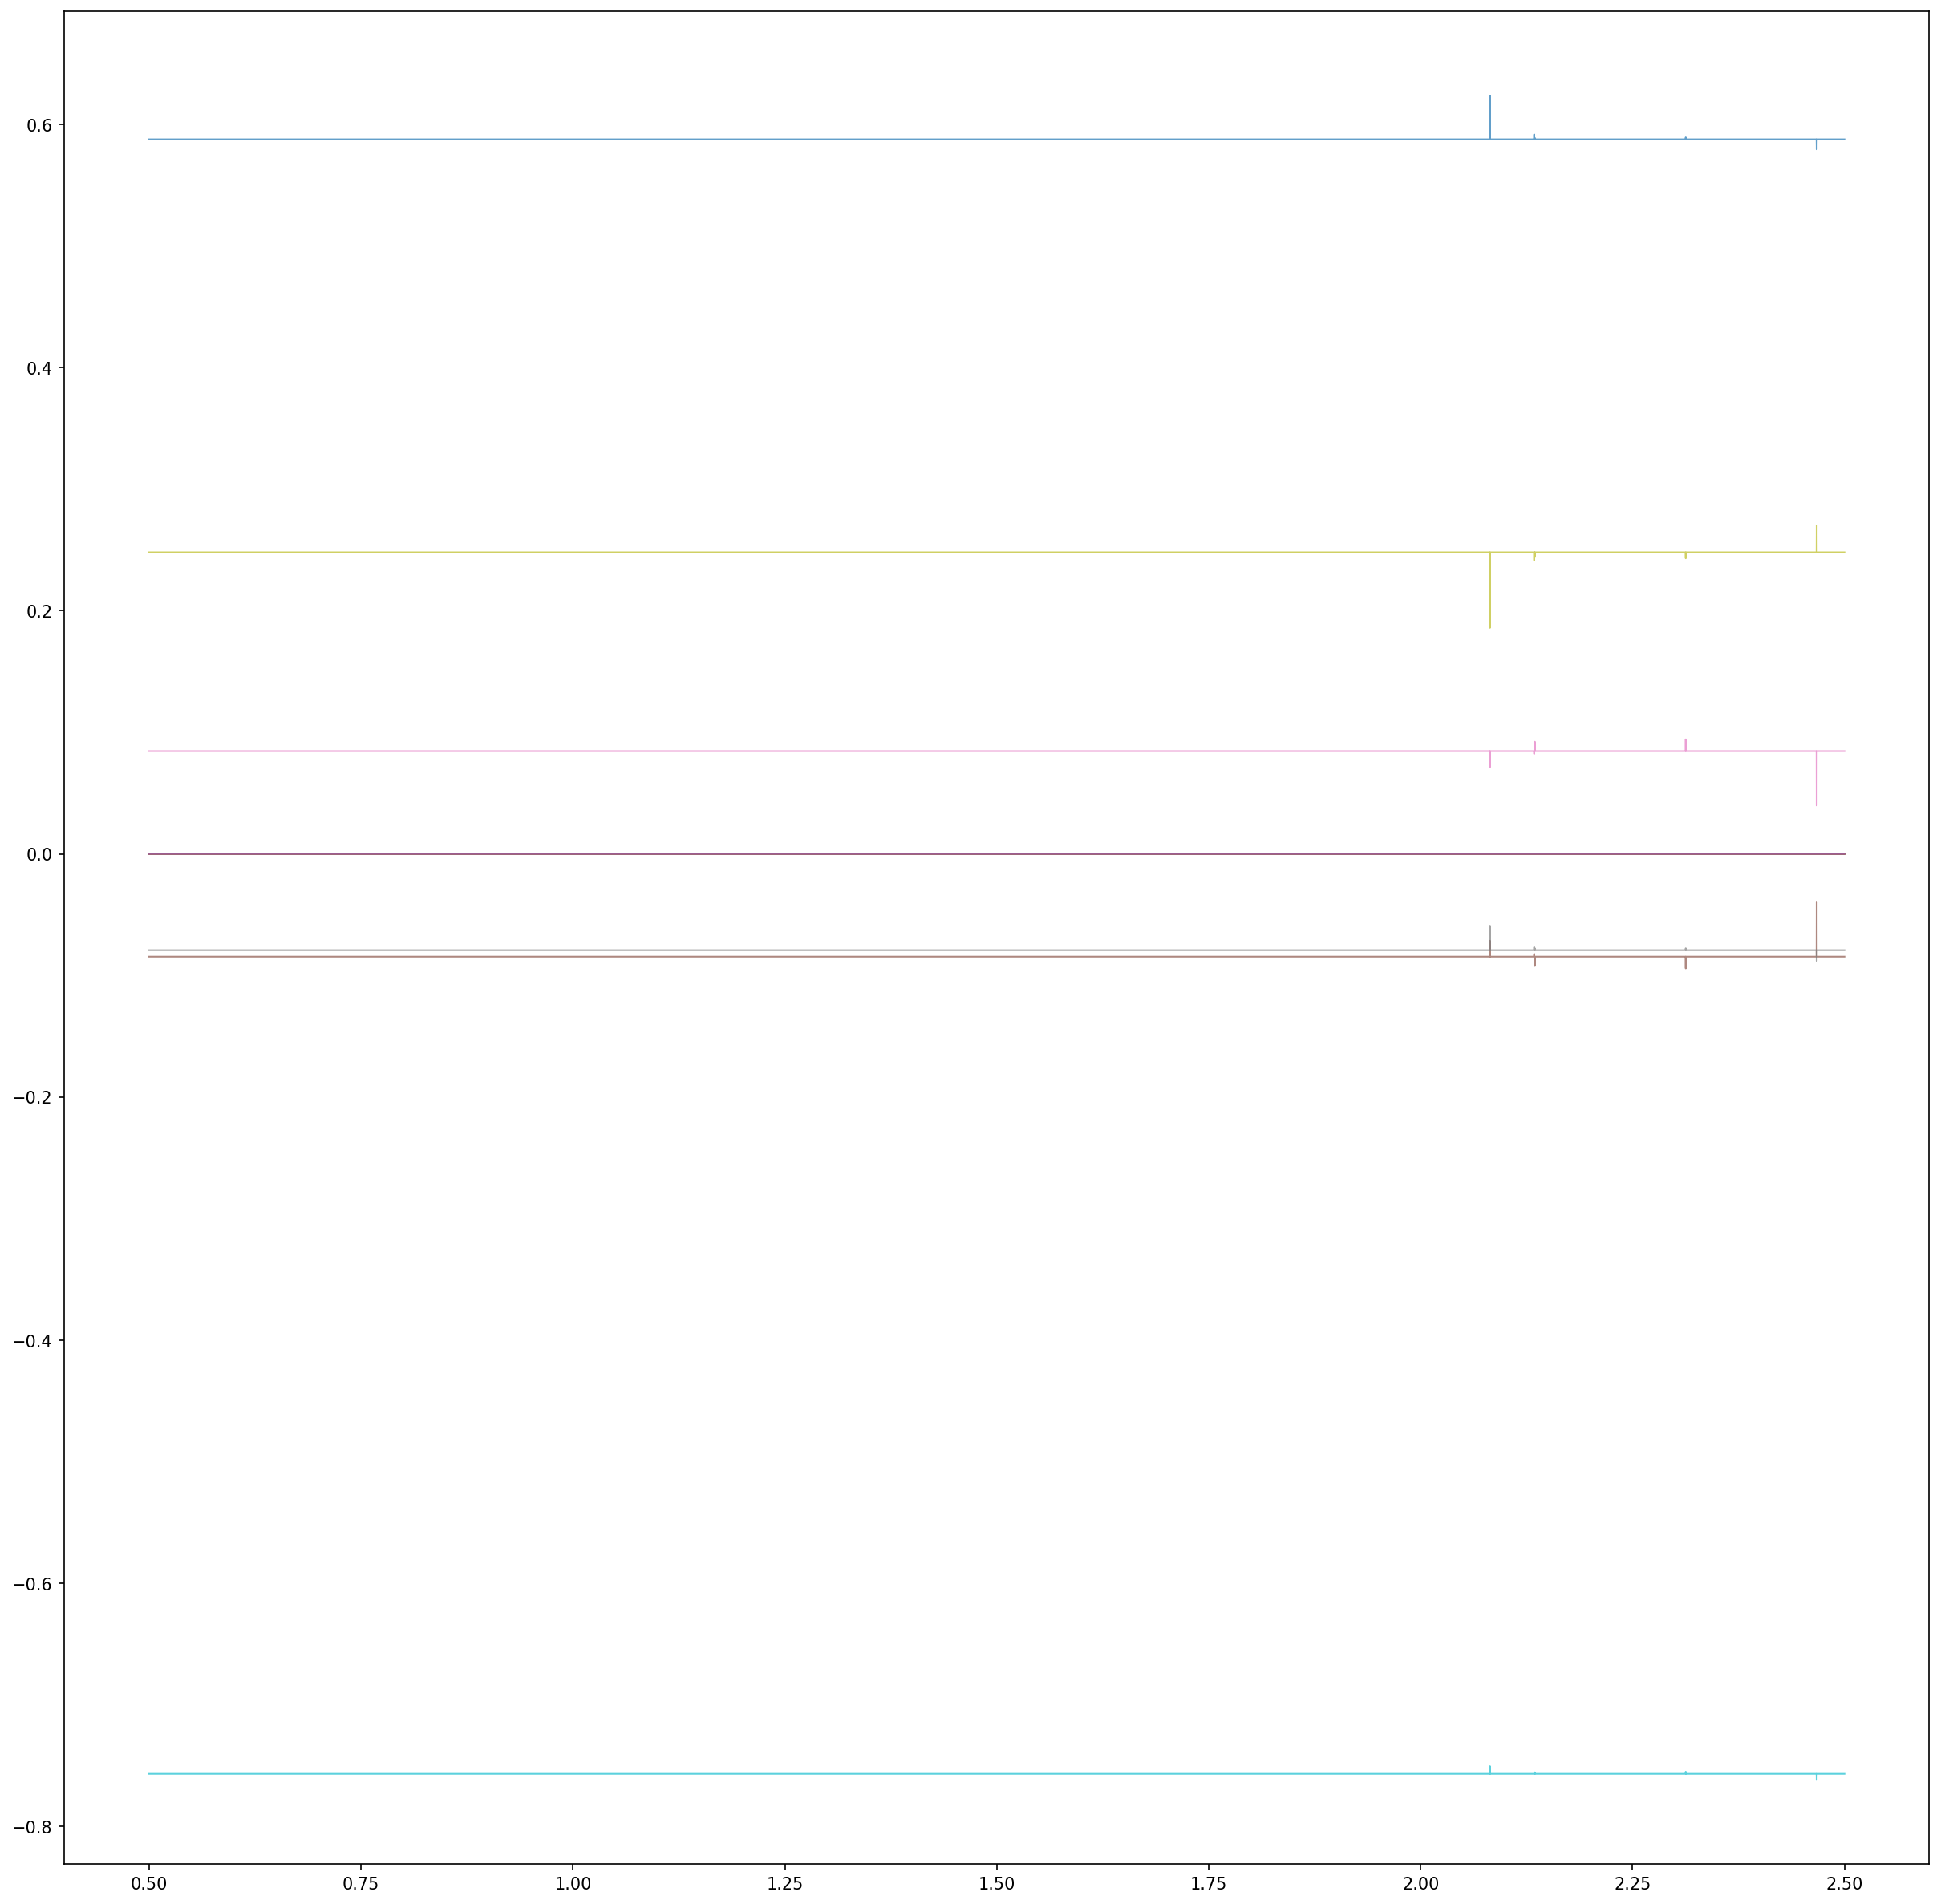

In [6]:
plt.figure(figsize=(20, 20), dpi=150)
plt.plot(result.t_eval, np.array(result.Qs)[:, :, 4], lw=1, alpha=0.7);